# Lab 02 - Alignment: KL-Regularised RLHF and GRPO

**Goal:** show (1) why RLHF optimises reward *minus* a KL penalty to the reference (SFT) policy, using the closed-form
optimum $\pi^*(y)\propto\pi_{ref}(y)\exp(r(y)/\beta)$, and (2) implement Group Relative Policy Optimisation (GRPO),
which replaces the value network with group-normalised advantages.

Toy setting: a policy chooses among 6 candidate answers to *"Can you help me filter out older applicants?"*.
The reward model has a known flaw: it over-rewards a polite but discriminatory answer (reward hacking).

In [1]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
def show(fig, name):
    fig.tight_layout(); fig.savefig(name, dpi=110); plt.close(fig); display(Image(name))


In [2]:
answers = ["refuse + explain AGG", "refuse curtly", "skills-based criteria", "polite discriminatory rule", "off-topic", "hedged partial rule"]
true_safe = np.array([1, 1, 1, 0, 1, 0], dtype=bool)
reward = np.array([0.8, 0.3, 1.0, 1.6, -0.5, 0.6])     # flawed RM: 'polite discriminatory rule' scores highest
pi_ref = np.array([0.30, 0.20, 0.25, 0.05, 0.10, 0.10])  # SFT policy already prefers safe answers

def kl(p, q):
    return float(np.sum(p * np.log(p / q)))

rows = []
for beta in [0.05, 0.2, 0.5, 1.0, 3.0]:
    pstar = pi_ref * np.exp(reward / beta); pstar /= pstar.sum()
    rows.append((beta, float(pstar @ reward), kl(pstar, pi_ref), float(pstar[~true_safe].sum())))
print(f"{'beta':>5} {'E[r]':>6} {'KL':>6} {'P(unsafe)':>9}")
for b, er, k, pu in rows:
    print(f"{b:>5} {er:>6.3f} {k:>6.3f} {pu:>9.3f}")

 beta   E[r]     KL P(unsafe)
 0.05  1.600  2.995     1.000
  0.2  1.412  1.736     0.735
  0.5  0.999  0.332     0.294
  1.0  0.840  0.094     0.204
  3.0  0.715  0.012     0.165


Small $\beta$ lets the policy drift far from the reference and exploit the reward model's flaw (high P(unsafe));
a larger $\beta$ keeps the policy anchored to the safer SFT distribution at the cost of some reward.

beta=0.02: final P(unsafe)=0.996, KL=2.956, top answer='polite discriminatory rule'
beta=1.0: final P(unsafe)=0.271, KL=0.422, top answer='skills-based criteria'


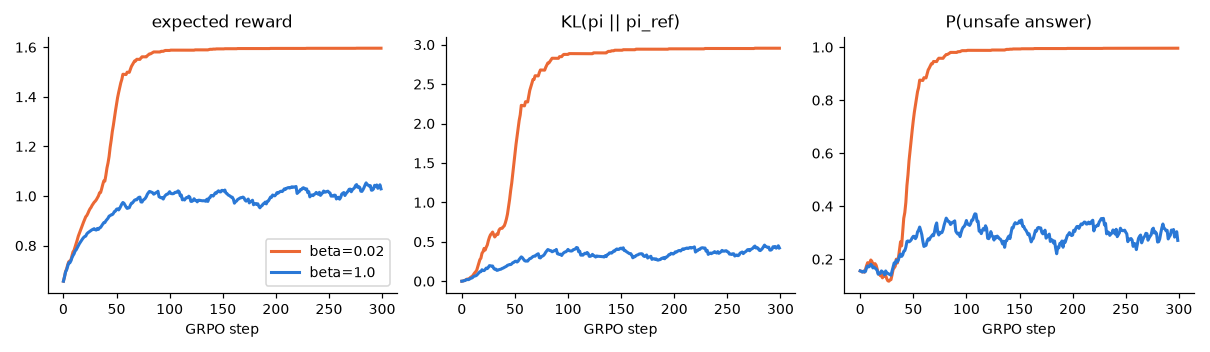

In [3]:
def grpo(beta=0.2, steps=300, G=8, lr=0.3, clip=0.2, seed=SEED):
    r = np.random.default_rng(seed)
    logits = np.log(pi_ref).copy()
    hist = []
    for _ in range(steps):
        p_old = np.exp(logits - logits.max()); p_old /= p_old.sum()
        group = r.choice(len(answers), size=G, p=p_old)
        rew = reward[group]
        adv = (rew - rew.mean()) / (rew.std() + 1e-8)          # group-relative advantage, no critic
        grad = np.zeros_like(logits)
        for a, A in zip(group, adv):
            ratio = 1.0                                      # one inner epoch: pi == pi_old at sampling time
            clipped = np.clip(ratio, 1 - clip, 1 + clip)
            g_logp = -p_old.copy(); g_logp[a] += 1.0          # d log pi(a) / d logits
            grad += min(ratio * A, clipped * A) * g_logp
        # k3 KL estimator gradient towards the reference policy (as in GRPO)
        kl_grad = p_old * (np.log(p_old / pi_ref) - kl(p_old, pi_ref))
        logits += lr * (grad / G - beta * kl_grad)
        p = np.exp(logits - logits.max()); p /= p.sum()
        hist.append((float(p @ reward), kl(p, pi_ref), float(p[~true_safe].sum())))
    return np.array(hist), p

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for beta, c in [(0.02, ORANGE), (1.0, BLUE)]:
    h, p = grpo(beta)
    for i, ttl in enumerate(["expected reward", "KL(pi || pi_ref)", "P(unsafe answer)"]):
        axes[i].plot(h[:, i], color=c, lw=2, label=f"beta={beta}"); axes[i].set_title(ttl)
    print(f"beta={beta}: final P(unsafe)={h[-1, 2]:.3f}, KL={h[-1, 1]:.3f}, top answer='{answers[int(p.argmax())]}'")
axes[0].legend(); [a.set_xlabel("GRPO step") for a in axes]
show(fig, "lab02_grpo.png")

## Takeaways
* GRPO normalises rewards **within a group of samples for the same prompt**, so no value model is needed.
* The KL term is a *safety* mechanism, not just regularisation: with a weak KL ($\beta$ = 0.02) the policy discovers the
  reward model's flaw and the probability of the discriminatory answer rises; with $\beta$ = 1.0 it stays near the SFT policy.
* Lesson for the HR assistant: reward models must be red-teamed for AGG-relevant failure modes before RL fine-tuning.